## 1. Impor Pustaka dan Pengaturan

In [6]:
from pathlib import Path
import time
import zipfile
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU (akan lambat).")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mengunduh dan Mengekstrak Dataset

In [7]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"
image_dir = data_dir / "dataset" / "Images"

if not zip_path.exists():
    urlretrieve(url, zip_path)

if not image_dir.exists():
    with zipfile.ZipFile(zip_path) as arsip:
        for nama in arsip.namelist():
            tujuan = (data_dir / nama).resolve()
            if not tujuan.is_relative_to(data_dir.resolve()):
                raise ValueError("Lokasi file ZIP tidak valid")
        arsip.extractall(data_dir)

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


## 3. Membaca Gambar dan Label
Setiap gambar dibaca dengan Pillow, diubah ke RGB, lalu di-resize menjadi 224×224.

In [8]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR
            )
            gambar.append(np.asarray(img))
            label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")
del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, "Periksa kelengkapan dataset"
assert np.all(np.bincount(y) == 100), "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


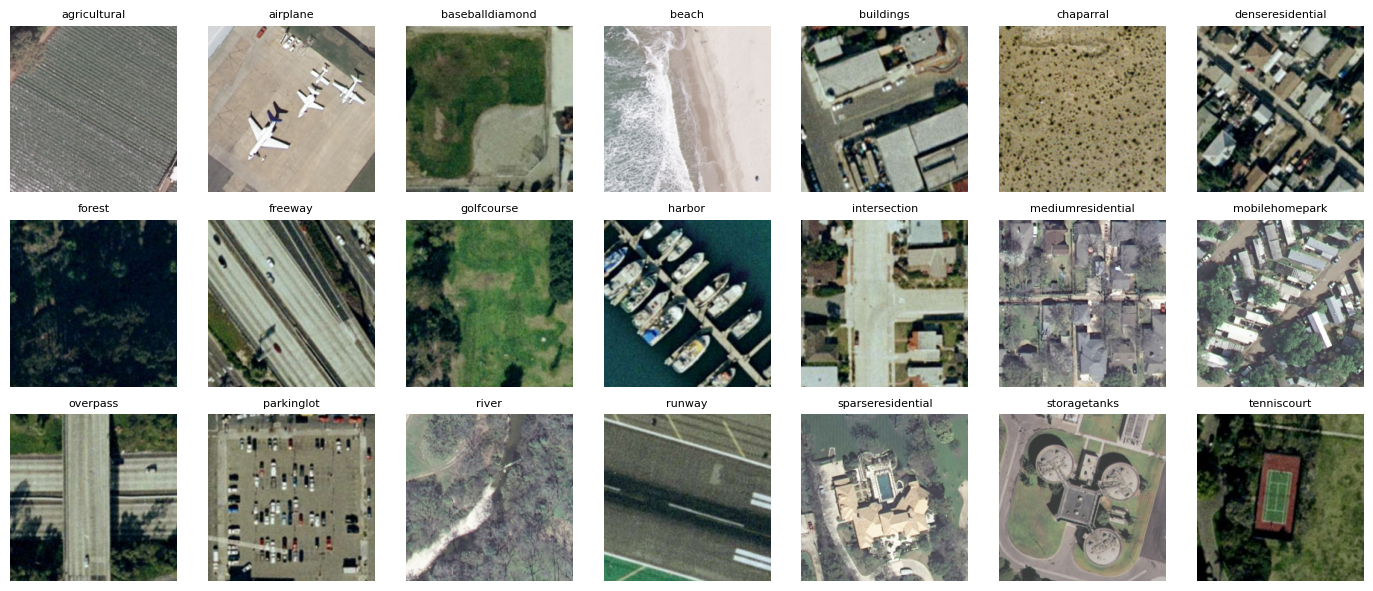

In [9]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Pembagian Data (70% latih, 15% validasi, 15% uji)

In [11]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_sisa, y_sisa, test_size=0.50, stratify=y_sisa, random_state=42
)

print("Train:", len(y_train), "Validation:", len(y_val), "Test:", len(y_test))

Train: 1470 Validation: 315 Test: 315


## 5. Fungsi Pembantu
Satu set fungsi dipakai untuk kedua arsitektur supaya perbandingannya adil. Hanya backbone dan fungsi `preprocess_input` yang berbeda, karena setiap arsitektur dilatih dengan skala piksel yang berbeda saat pretraining di ImageNet.

In [13]:
def bangun_model(arsitektur, preprocess, nama):
    base_model = arsitektur(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = preprocess(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(len(nama_kelas), activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name=nama)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def latih(model):
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
    mulai = time.time()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=2
    )
    waktu = time.time() - mulai
    print("Epoch dijalankan:", len(history.history["loss"]))
    print(f"Waktu pelatihan: {waktu:.1f} detik")
    return history, waktu


def plot_history(history, judul):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="Train")
        ax.plot(epochs, history.history["val_" + metric], label="Validation")
        ax.set(xlabel="Epoch", ylabel=metric, title=metric)
        ax.legend()
    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()


def evaluasi(model, judul):
    test_loss, test_acc = model.evaluate(
        x_test, y_test, batch_size=BATCH_SIZE, verbose=0
    )
    probabilitas = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    y_pred = probabilitas.argmax(axis=1)

    print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2%}")
    print(classification_report(
        y_test, y_pred, target_names=nama_kelas, zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=nama_kelas,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False,
        ax=ax
    )
    ax.set_title(judul)
    plt.tight_layout()
    plt.show()

    macro_f1 = f1_score(y_test, y_pred, average="macro")
    return test_loss, test_acc, macro_f1, y_pred, probabilitas


def tampilkan_prediksi(y_pred, probabilitas, jumlah=8):
    fig, axes = plt.subplots(2, 4, figsize=(13, 6))
    for i, ax in enumerate(axes.flat[:jumlah]):
        ax.imshow(x_test[i])
        ax.set_title(
            f"Asli: {nama_kelas[y_test[i]]}\n"
            f"Pred: {nama_kelas[y_pred[i]]} "
            f"({probabilitas[i].max():.0%})",
            fontsize=9,
            color="green" if y_test[i] == y_pred[i] else "red"
        )
        ax.axis("off")
    plt.tight_layout()
    plt.show()


hasil = {}

## 6. Model 1: VGG16 (Ketentuan No. 1)
VGG16 terdiri dari blok-blok konvolusi 3×3 yang ditumpuk dalam, diselingi max pooling. Bobotnya besar (sekitar 14,7 juta parameter pada bagian konvolusi), tetapi strukturnya sederhana dan mudah dipahami.

In [14]:
tf.keras.utils.set_random_seed(42)

model_vgg = bangun_model(
    tf.keras.applications.VGG16,
    tf.keras.applications.vgg16.preprocess_input,
    "vgg16_ucmerced"
)
model_vgg.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 21)        │     10,773 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:
history_vgg, waktu_vgg = latih(model_vgg)

Epoch 1/10
92/92 - 22s - 237ms/step - accuracy: 0.2197 - loss: 5.4677 - val_accuracy: 0.5968 - val_loss: 1.6493
Epoch 2/10
92/92 - 7s - 71ms/step - accuracy: 0.5694 - loss: 1.9561 - val_accuracy: 0.7810 - val_loss: 0.7605
Epoch 3/10
92/92 - 7s - 72ms/step - accuracy: 0.7177 - loss: 1.1429 - val_accuracy: 0.8667 - val_loss: 0.4817
Epoch 4/10
92/92 - 7s - 72ms/step - accuracy: 0.7918 - loss: 0.7067 - val_accuracy: 0.8571 - val_loss: 0.4151
Epoch 5/10
92/92 - 7s - 72ms/step - accuracy: 0.8327 - loss: 0.5810 - val_accuracy: 0.8921 - val_loss: 0.3103
Epoch 6/10
92/92 - 7s - 73ms/step - accuracy: 0.8748 - loss: 0.4343 - val_accuracy: 0.9016 - val_loss: 0.3013
Epoch 7/10
92/92 - 7s - 73ms/step - accuracy: 0.8918 - loss: 0.3687 - val_accuracy: 0.9175 - val_loss: 0.2471
Epoch 8/10
92/92 - 7s - 73ms/step - accuracy: 0.9075 - loss: 0.3024 - val_accuracy: 0.9270 - val_loss: 0.2289
Epoch 9/10
92/92 - 7s - 81ms/step - accuracy: 0.9211 - loss: 0.2144 - val_accuracy: 0.9302 - val_loss: 0.2261
Epoch 10

In [ ]:
plot_history(history_vgg, "VGG16 - Loss dan Akurasi")

Test loss: 0.2523 | Test accuracy: 91.43%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       0.94      1.00      0.97        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.69      0.73      0.71        15
        chaparral       1.00      0.93      0.97        15
 denseresidential       0.75      0.80      0.77        15
           forest       0.88      1.00      0.94        15
          freeway       1.00      0.93      0.97        15
       golfcourse       0.93      0.87      0.90        15
           harbor       1.00      1.00      1.00        15
     intersection       0.63      0.80      0.71        15
mediumresidential       0.82      0.93      0.88        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       1.00      0.87      0.93        15
       parkin

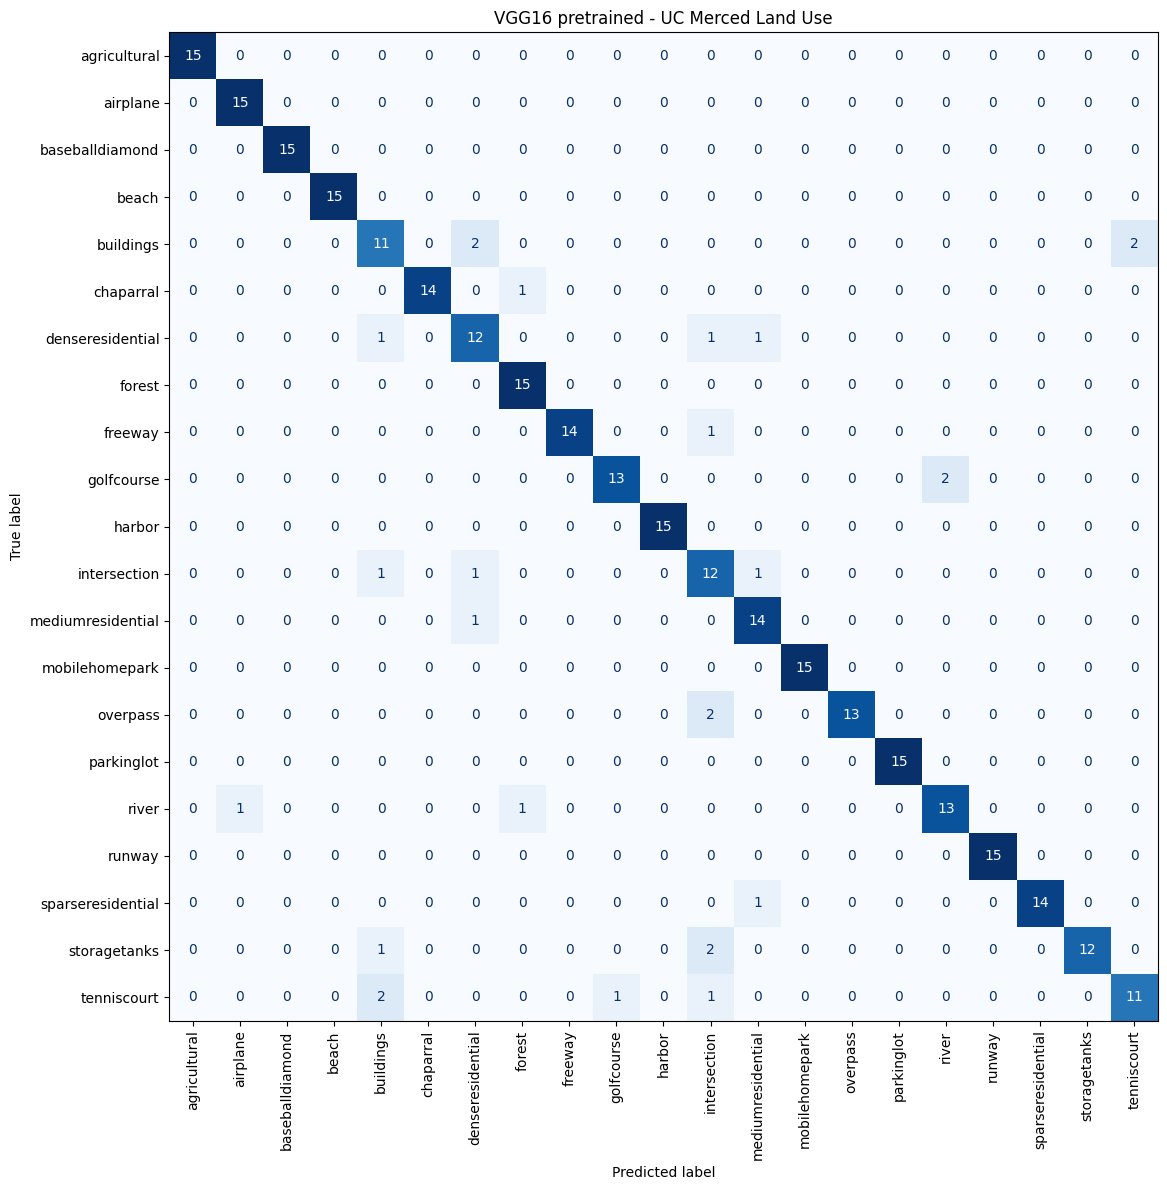

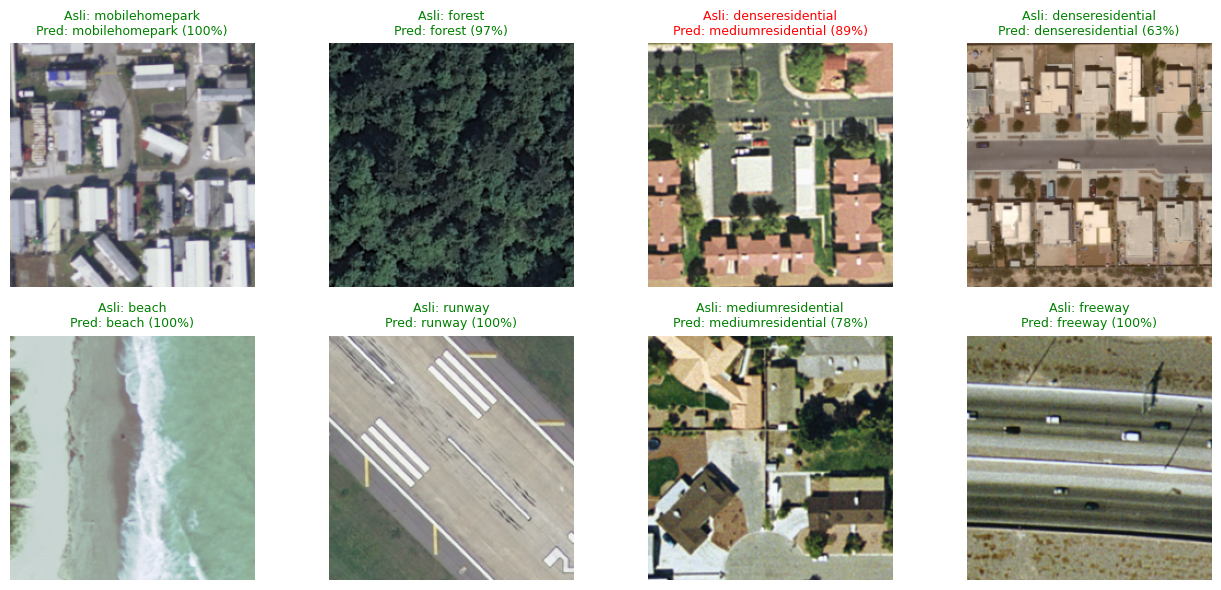

In [16]:
loss_vgg, acc_vgg, f1_vgg, pred_vgg, prob_vgg = evaluasi(
    model_vgg, "VGG16 pretrained - UC Merced Land Use"
)
tampilkan_prediksi(pred_vgg, prob_vgg)

hasil["VGG16"] = {
    "Test accuracy": acc_vgg,
    "Test loss": loss_vgg,
    "Macro F1": f1_vgg,
    "Total parameter": model_vgg.count_params(),
    "Parameter dilatih": int(sum(np.prod(w.shape) for w in model_vgg.trainable_weights)),
    "Epoch": len(history_vgg.history["loss"]),
    "Waktu latih (detik)": waktu_vgg,
}

## 7. Model 2: MobileNetV2 (Ketentuan No. 2)
MobileNetV2 dirancang untuk perangkat dengan sumber daya terbatas. Model ini memakai *depthwise separable convolution* dan *inverted residual block*, sehingga jumlah parameternya jauh lebih kecil daripada VGG16.

In [17]:
tf.keras.utils.set_random_seed(42)

model_mobile = bangun_model(
    tf.keras.applications.MobileNetV2,
    tf.keras.applications.mobilenet_v2.preprocess_input,
    "mobilenetv2_ucmerced"
)
model_mobile.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,885 (8.72 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
history_mobile, waktu_mobile = latih(model_mobile)

Epoch 1/10
92/92 - 23s - 255ms/step - accuracy: 0.5707 - loss: 1.5204 - val_accuracy: 0.8921 - val_loss: 0.4266
Epoch 2/10
92/92 - 2s - 19ms/step - accuracy: 0.9034 - loss: 0.3731 - val_accuracy: 0.9460 - val_loss: 0.2426
Epoch 3/10
92/92 - 2s - 18ms/step - accuracy: 0.9517 - loss: 0.2223 - val_accuracy: 0.9460 - val_loss: 0.1859
Epoch 4/10
92/92 - 2s - 19ms/step - accuracy: 0.9653 - loss: 0.1610 - val_accuracy: 0.9587 - val_loss: 0.1576
Epoch 5/10
92/92 - 2s - 19ms/step - accuracy: 0.9776 - loss: 0.1157 - val_accuracy: 0.9587 - val_loss: 0.1496
Epoch 6/10
92/92 - 2s - 19ms/step - accuracy: 0.9878 - loss: 0.0824 - val_accuracy: 0.9556 - val_loss: 0.1434
Epoch 7/10
92/92 - 2s - 18ms/step - accuracy: 0.9918 - loss: 0.0631 - val_accuracy: 0.9587 - val_loss: 0.1347
Epoch 8/10
92/92 - 2s - 18ms/step - accuracy: 0.9925 - loss: 0.0551 - val_accuracy: 0.9619 - val_loss: 0.1238
Epoch 9/10
92/92 - 2s - 18ms/step - accuracy: 0.9952 - loss: 0.0444 - val_accuracy: 0.9714 - val_loss: 0.1188
Epoch 10

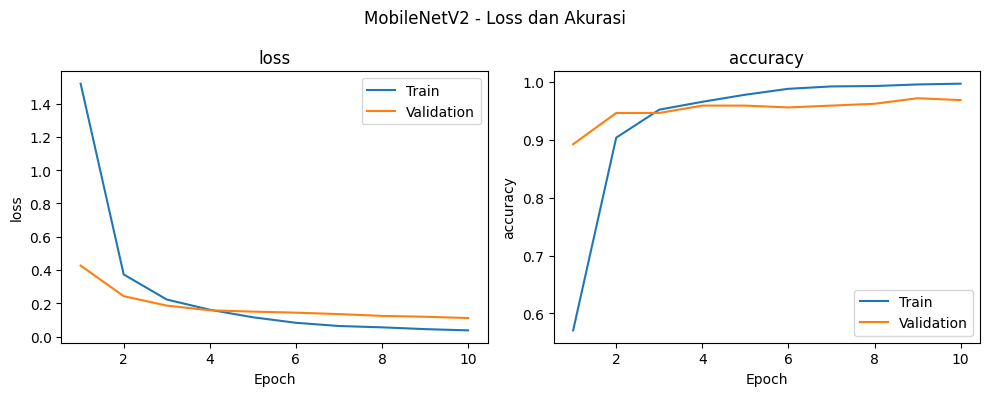

In [19]:
plot_history(history_mobile, "MobileNetV2 - Loss dan Akurasi")

Test loss: 0.1559 | Test accuracy: 95.56%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       0.94      1.00      0.97        15
            beach       1.00      1.00      1.00        15
        buildings       1.00      0.93      0.97        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.88      0.93      0.90        15
           forest       1.00      1.00      1.00        15
          freeway       0.93      0.93      0.93        15
       golfcourse       1.00      0.87      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       0.88      0.93      0.90        15
mediumresidential       0.72      0.87      0.79        15
   mobilehomepark       1.00      0.93      0.97        15
         overpass       0.93      0.93      0.93        15
       parkin

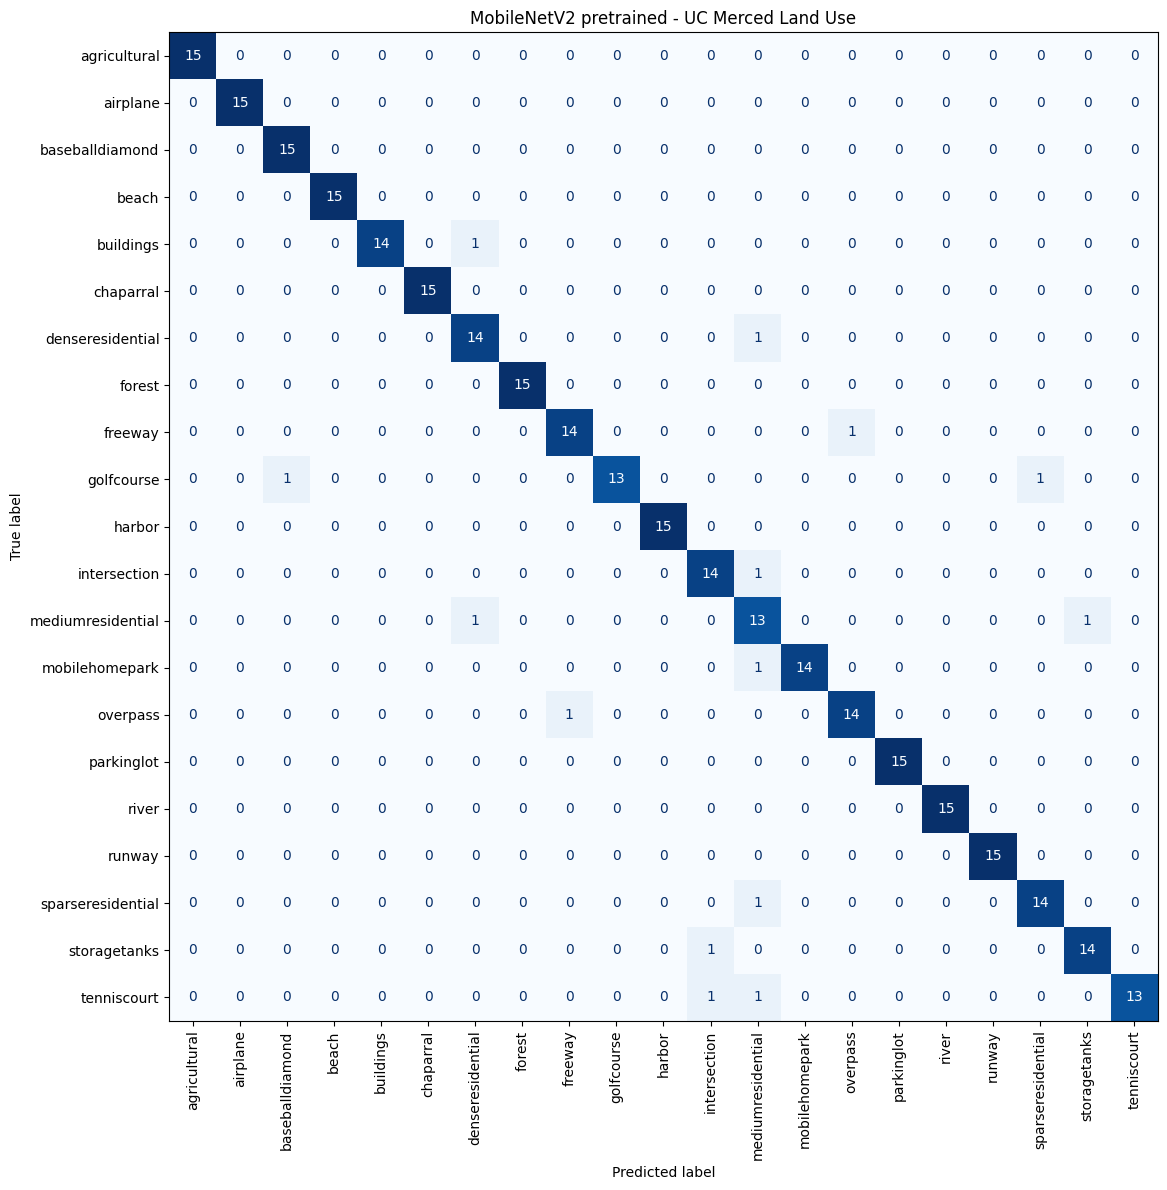

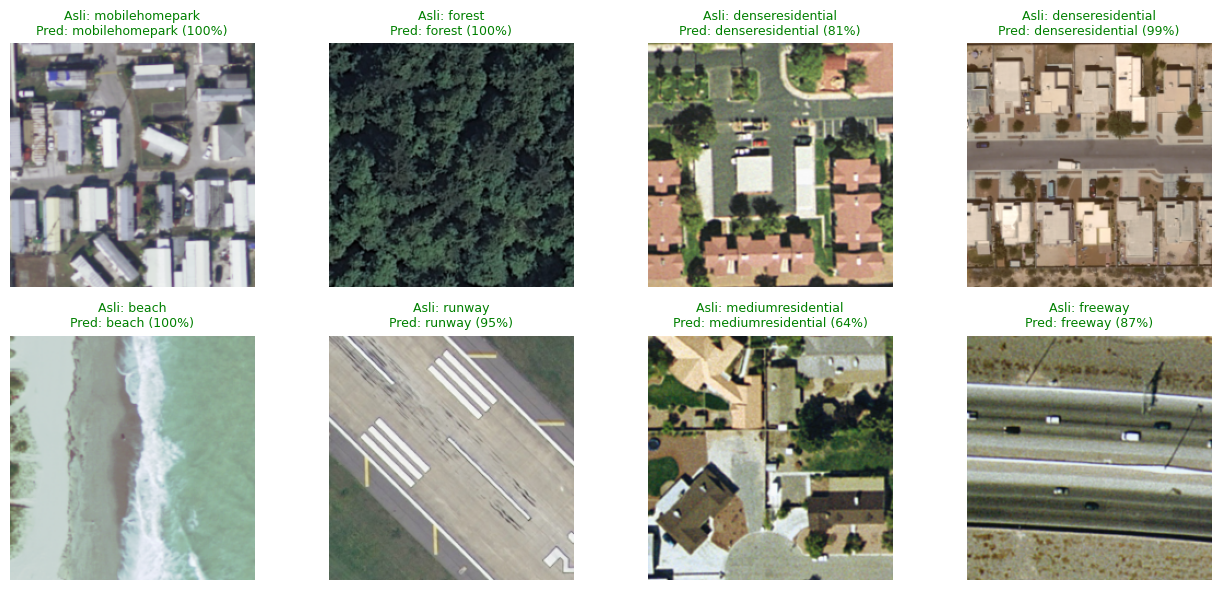

In [20]:
loss_mobile, acc_mobile, f1_mobile, pred_mobile, prob_mobile = evaluasi(
    model_mobile, "MobileNetV2 pretrained - UC Merced Land Use"
)
tampilkan_prediksi(pred_mobile, prob_mobile)

hasil["MobileNetV2"] = {
    "Test accuracy": acc_mobile,
    "Test loss": loss_mobile,
    "Macro F1": f1_mobile,
    "Total parameter": model_mobile.count_params(),
    "Parameter dilatih": int(sum(np.prod(w.shape) for w in model_mobile.trainable_weights)),
    "Epoch": len(history_mobile.history["loss"]),
    "Waktu latih (detik)": waktu_mobile,
}

## 8. Perbandingan Hasil

In [21]:
tabel = pd.DataFrame(hasil).T
tabel["Test accuracy"] = tabel["Test accuracy"].map("{:.2%}".format)
tabel["Test loss"] = tabel["Test loss"].astype(float).map("{:.4f}".format)
tabel["Macro F1"] = tabel["Macro F1"].astype(float).map("{:.4f}".format)
tabel["Waktu latih (detik)"] = tabel["Waktu latih (detik)"].astype(float).round(1)
tabel

,Test accuracy,Test loss,Macro F1,Total parameter,Parameter dilatih,Epoch,Waktu latih (detik)
VGG16,91.43%,0.2523,0.9159,14725461.0,10773.0,10.0,83.3
MobileNetV2,95.56%,0.1559,0.9564,2284885.0,26901.0,10.0,39.4


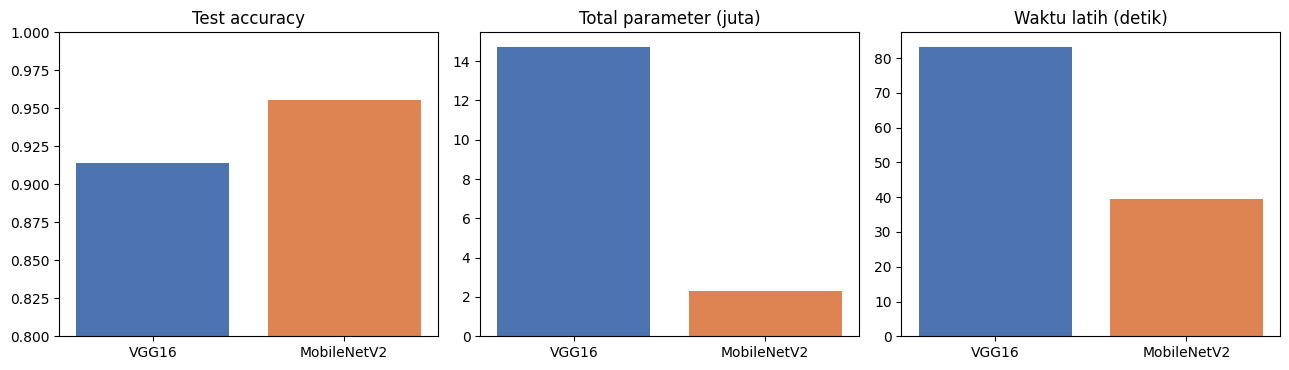

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
nama = list(hasil.keys())

axes[0].bar(nama, [hasil[n]["Test accuracy"] for n in nama], color=["#4C72B0", "#DD8452"])
axes[0].set(title="Test accuracy", ylim=(0.8, 1.0))

axes[1].bar(nama, [hasil[n]["Total parameter"] / 1e6 for n in nama], color=["#4C72B0", "#DD8452"])
axes[1].set(title="Total parameter (juta)")

axes[2].bar(nama, [hasil[n]["Waktu latih (detik)"] for n in nama], color=["#4C72B0", "#DD8452"])
axes[2].set(title="Waktu latih (detik)")

plt.tight_layout()
plt.show()

In [ ]:
# Ringkasan otomatis; angka berasal dari hasil eksekusi di atas.
terbaik = max(hasil, key=lambda n: hasil[n]["Test accuracy"])
print(f"Akurasi uji tertinggi: {terbaik} ({hasil[terbaik]['Test accuracy']:.2%})")
print(f"Selisih akurasi VGG16 - MobileNetV2: "
      f"{(hasil['VGG16']['Test accuracy'] - hasil['MobileNetV2']['Test accuracy']) * 100:+.2f} poin persen")
print(f"Rasio parameter VGG16 / MobileNetV2: "
      f"{hasil['VGG16']['Total parameter'] / hasil['MobileNetV2']['Total parameter']:.1f}x")
print("Catatan: modul Pertemuan 3 melaporkan ResNet50 mencapai akurasi uji 95.24% "
      "pada pembagian data yang sama (sebagai pembanding).")